In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())

Saving project5_customer_activity.csv to project5_customer_activity (4).csv
Dataset shape: (12, 6)


,customer_id,business_type,join_date,activity_date,activity_type,amount
0,C001,Online Shopping,2026-01-10,2026-01-12,Purchase,25000
1,C001,Online Shopping,2026-01-10,2026-02-10,Purchase,15000
2,C001,Online Shopping,2026-01-10,2026-03-05,Purchase,20000
3,C002,Online Shopping,2026-01-15,2026-01-18,Purchase,30000
4,C003,Mobile Accessories,2026-01-20,2026-01-20,Purchase,8000


In [2]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customer_id    12 non-null     object
 1   business_type  12 non-null     object
 2   join_date      12 non-null     object
 3   activity_date  12 non-null     object
 4   activity_type  12 non-null     object
 5   amount         12 non-null     int64 
dtypes: int64(1), object(5)
memory usage: 708.0+ bytes

Missing values:
customer_id      0
business_type    0
join_date        0
activity_date    0
activity_type    0
amount           0
dtype: int64

Duplicate rows:
0

Summary statistics:


,amount
count,12.000000
mean,14583.333333
std,13249.070865
min,0.000000
25%,5000.000000
50%,10000.000000
75%,21250.000000
max,45000.000000


In [3]:
df["join_date"] = pd.to_datetime(df["join_date"])
df["activity_date"] = pd.to_datetime(df["activity_date"])

print(df.dtypes)

customer_id              object
business_type            object
join_date        datetime64[ns]
activity_date    datetime64[ns]
activity_type            object
amount                    int64
dtype: object


In [4]:
customer_summary = df.groupby(
      ["customer_id", "business_type", "join_date"]
      ).agg(
          total_amount=("amount", "sum"),
              activity_count=("activity_type", "count"),
                  last_activity=("activity_date", "max")
                  ).reset_index()

print(customer_summary)

  customer_id         business_type  join_date  total_amount  activity_count  \
0        C001       Online Shopping 2026-01-10         60000               3   
1        C002       Online Shopping 2026-01-15         30000               1   
2        C003    Mobile Accessories 2026-01-20         20000               2   
3        C004    Mobile Accessories 2026-01-22         45000               1   
4        C005  Subscription Service 2026-01-25         15000               3   
5        C006  Subscription Service 2026-01-28          5000               2   

  last_activity  
0    2026-03-05  
1    2026-01-18  
2    2026-03-15  
3    2026-01-22  
4    2026-03-25  
5    2026-02-28  


In [5]:
cancelled = (
      df[df["activity_type"] == "Subscription Cancelled"]
          ["customer_id"]
              .unique()
              )

customer_summary["cancelled"] = (
                  customer_summary["customer_id"].isin(cancelled)
                  )

print(customer_summary)

  customer_id         business_type  join_date  total_amount  activity_count  \
0        C001       Online Shopping 2026-01-10         60000               3   
1        C002       Online Shopping 2026-01-15         30000               1   
2        C003    Mobile Accessories 2026-01-20         20000               2   
3        C004    Mobile Accessories 2026-01-22         45000               1   
4        C005  Subscription Service 2026-01-25         15000               3   
5        C006  Subscription Service 2026-01-28          5000               2   

  last_activity  cancelled  
0    2026-03-05      False  
1    2026-01-18      False  
2    2026-03-15      False  
3    2026-01-22      False  
4    2026-03-25      False  
5    2026-02-28       True  


In [6]:
purchase_counts = df[df["activity_type"] == "Purchase"].groupby("customer_id").size()

customer_summary["purchase_count"] = customer_summary["customer_id"].map(purchase_counts).fillna(0).astype(int)

customer_summary["customer_status"] = "Single Purchase"

customer_summary.loc[customer_summary["purchase_count"] > 1, "customer_status"] = "Repeat Purchaser"

customer_summary.loc[(customer_summary["business_type"] == "Subscription Service") & (~customer_summary["cancelled"]), "customer_status"] = "Retained"

customer_summary.loc[customer_summary["cancelled"], "customer_status"] = "Churned"

display(customer_summary)

,customer_id,business_type,join_date,total_amount,activity_count,last_activity,cancelled,purchase_count,customer_status
0,C001,Online Shopping,2026-01-10,60000,3,2026-03-05,False,3,Repeat Purchaser
1,C002,Online Shopping,2026-01-15,30000,1,2026-01-18,False,1,Single Purchase
2,C003,Mobile Accessories,2026-01-20,20000,2,2026-03-15,False,2,Repeat Purchaser
3,C004,Mobile Accessories,2026-01-22,45000,1,2026-01-22,False,1,Single Purchase
4,C005,Subscription Service,2026-01-25,15000,3,2026-03-25,False,0,Retained
5,C006,Subscription Service,2026-01-28,5000,2,2026-02-28,True,0,Churned


In [7]:
product_customers = customer_summary[customer_summary["business_type"] != "Subscription Service"]
subscription_customers = customer_summary[customer_summary["business_type"] == "Subscription Service"]

repeat_rate = (product_customers["purchase_count"].gt(1).sum() / len(product_customers)) * 100
retention_rate = (subscription_customers["customer_status"].eq("Retained").sum() / len(subscription_customers)) * 100

print("Repeat Purchase Rate:", repeat_rate, "%")
print("Subscription Retention Rate:", retention_rate, "%")

Repeat Purchase Rate: 50.0 %
Subscription Retention Rate: 50.0 %


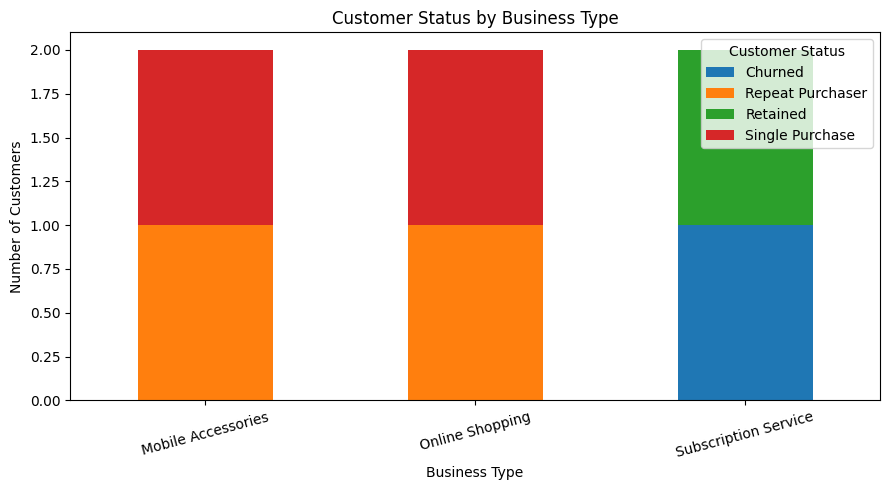

In [8]:
import matplotlib.pyplot as plt

status_table = pd.crosstab(customer_summary["business_type"], customer_summary["customer_status"])

status_table.plot(kind="bar", stacked=True, figsize=(9,5))

plt.title("Customer Status by Business Type")
plt.xlabel("Business Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

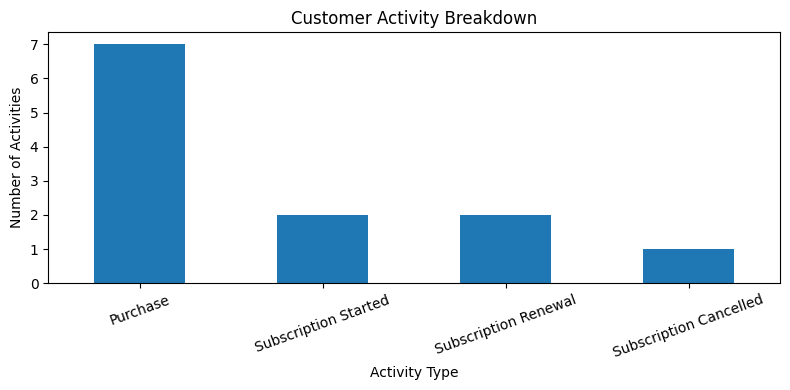

In [9]:
activity_counts = df["activity_type"].value_counts()

activity_counts.plot(kind="bar", figsize=(8,4))
plt.title("Customer Activity Breakdown")
plt.xlabel("Activity Type")
plt.ylabel("Number of Activities")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()